# 15. Graph machine learning

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/15_ml.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/15_ml.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/banner-15.svg" alt="duckOSM notebook manual, chapter 15: Graph machine learning" width="100%">

| **You learn** | the junction graph and the turn graph; the feature arrays and how their row numbers map to the ids; your own feature columns; the PyTorch Geometric, DGL and NumPy formats; a graph neural network that learns the speed limits; the predictions on the map |
|---|---|
| **Time** | about 4 minutes (the install of PyTorch Geometric included) |
| **Extras** | `duckosm[ml,viz]` (the install cell installs them) |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
# roadstyle (the maps) also comes from its nightly wheel, so the newest roadstyle parts work with no roadstyle release.
import importlib.util, json, os, urllib.request
def nightly_wheel(repo="Khoshkhah/duckOSM", name=".whl"):        # the address of the newest nightly wheel of a repository
    release = json.load(urllib.request.urlopen(f"https://api.github.com/repos/{repo}/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if name in a["name"] and a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[ml,viz] @ {nightly_wheel()}"
    %pip install -q --force-reinstall --no-deps "roadstyle @ {nightly_wheel('Khoshkhah/roadstyle', 'manylinux')}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version
# The network of chapter 1 (monaco.duckdb). The chapter opens it. When you run this chapter alone (in Colab), the file
# is not there, so this cell makes it one time.
if not os.path.exists("monaco.duckdb") or not duckosm.open("monaco.duckdb").has_mode("driving", "walking", "cycling"):
    duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], path="monaco.duckdb")

duckosm 0.8.0


## A duckOSM network as a graph for a model

A **graph** is a set of dots (the **vertices**) joined by lines (the **arcs**). A duckOSM network is a graph: its
nodes and its edges are dots and lines.

**Graph machine learning** trains a model that learns a value for each vertex or each arc. It uses two things: the
numbers that describe each vertex or arc (its **features**, for example the length of an edge), and the values of its
neighbors. A duckOSM network is a good case for it, because an edge is like the edges that it connects to: a quiet
side street is next to other quiet streets. Some questions that a model can answer:

- Which speed limit has an edge where OSM has no `maxspeed` tag?
- How many vehicles use an edge that has no traffic sensor, when its neighbors have sensors?
- Which road class has an edge that OSM tags badly?

**The words of this chapter.** This chapter speaks about two worlds: the duckOSM network and the graph that a model
reads. Each word has one meaning, and the chapter uses only these words:

| Word | Means | World |
|---|---|---|
| node | a junction of the duckOSM network (`node_id`, the table `nodes`) | duckOSM |
| edge | one direction of a road in duckOSM (`edge_id`) | duckOSM |
| turn | a legal move from one edge to the next edge (a row of `edge_graph`) | duckOSM |
| vertex | a dot of the graph that a model reads | graph |
| arc | a line from one vertex to another vertex | graph |
| row number | the position of a vertex or an arc in the tables (0, 1, 2 ...) | graph |
| feature | a number that describes a vertex or an arc | graph |
| target | the value that the model learns and predicts (here the speed limit) | graph |

PyTorch Geometric and DGL call a vertex a node: `num_nodes` is the number of vertices, and `x` holds the vertex
features. This chapter writes "vertex" for the graph and keeps "node" for duckOSM.

There are two ways to make a graph from a duckOSM network. duckOSM gives both.

<img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/ml-two-graphs.svg" alt="The junction graph: each node is a vertex, each edge is an arc. The turn graph: each edge becomes a vertex, each turn is an arc" width="100%">

The table compares the two graphs: what a vertex and an arc are in each one, and which numbers describe them.

| Graph | A vertex is | An arc is | Vertex features | Arc features |
|---|---|---|---|---|
| junction graph, `graph="nodes"` | a node | an edge | `lon`, `lat` | the columns of the edge that you choose |
| turn graph, `graph="turns"` | an edge | a turn | the columns of the edge that you choose | `cost`: the seconds of the first edge |

- **Junction graph:** each node is a vertex, and each edge is an arc.
- **Turn graph:** each edge becomes a vertex, and each turn is an arc.

Use the **junction graph** when the target belongs to a place: a node, a crossing, a bus stop at a node. Use the
**turn graph** when the target belongs to an edge: a speed, a flow, a road class. In the turn graph each edge becomes
a vertex, so the usual vertex models of a graph library (the libraries call them "node classification" and "node regression") work on edges. A
forbidden move is not a turn, so it has no arc, and a value does not flow across a move that a car cannot make.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-key.svg" width="18" height="18" alt=""> **Key idea**
>
> Each graph keeps the `edge_id`. The model predicts one value for each row number, and the `edge_id` of that row number takes the value back to its edge. Then the value joins to the network, to the map and to your own data (chapter 4).

## How a model reads a graph: three tables

A model cannot read a drawing of dots and lines. A graph library keeps a graph as three tables of numbers (in
Python, a table of numbers is an array with rows and columns). The small junction graph below has 3 nodes, which are
the vertices 0, 1 and 2, and 3 edges, which are the arcs: 0 to 1, 1 to 2, and 2 to 0.

**1. The arcs.** A table of two rows: the start vertex and the end vertex of each arc, with one column for each arc.
Arc 0 goes from vertex 0 to vertex 1. (PyTorch Geometric keeps it in this form, as `edge_index`. `graph_arrays` gives
the two rows as two arrays, `src` and `dst`.)

| | arc 0 | arc 1 | arc 2 |
|---|---|---|---|
| from | 0 | 1 | 2 |
| to | 1 | 2 | 0 |

**2. The vertex features.** One row for each vertex, with the numbers that describe it.

| vertex | lon | lat |
|---|---|---|
| 0 | 7.42 | 43.73 |
| 1 | 7.43 | 43.74 |
| 2 | 7.41 | 43.74 |

**3. The arc features.** One row for each arc, in the same order as the arcs.

| arc | length_m | maxspeed_kmh | lanes |
|---|---|---|---|
| 0 | 120 | 50 | 2 |
| 1 | 80 | 30 | 1 |
| 2 | 200 | 50 | 2 |

In the arcs table, a vertex has no OSM id. It has its **row number** in the vertex features table: the first row is
vertex 0, the second row is vertex 1, and so on. A graph library needs these small numbers, from 0 to the number of
vertices minus 1. So duckOSM keeps one more list, with the duckOSM id of each row number:

| row number (the vertex in the tables) | `node_id` (the node in duckOSM) |
|---|---|
| 0 | 21911886 |
| 1 | 21912089 |
| 2 | 21912095 |

The arc "from 0 to 1" is then the edge from node 21911886 to node 21912089. In the same way, a list of `edge_id`
gives the edge of each arc. When the model predicts a value for row number 1, this list says which node (or which
edge) it is, so the value goes back to the network.

`graph_arrays` gives these tables for Monaco: 1,768 vertices and 2,840 arcs in the junction graph. `to_pyg` and
`to_dgl` give the same tables in the form that PyTorch Geometric and DGL read.

## Open the network of chapter 1

Chapter 1 builds Monaco with three modes (driving, walking and cycling) and saves it as `monaco.duckdb`. This chapter
opens that file with `duckosm.open`: it builds nothing. The graphs use the driving network.

In [2]:
net = duckosm.open("monaco.duckdb")    # the network of chapter 1: Monaco, three modes
net                                    # the card

Network('monaco.duckdb', 52.7 MB, driving 2840 edges, walking 11938 edges, cycling 11305 edges)

The driving network of Monaco has 2840 edges. Each edge becomes one arc of the junction graph and one vertex of
the turn graph.

## The feature arrays: `graph_arrays`

`duckosm.ml.graph_arrays` gives the three tables of the section above as NumPy arrays in a dict: `src` and `dst`
(the arcs), `x` (the vertex features) and `edge_attr` (the arc features), with the duckOSM id of each row number. The
PyTorch Geometric and DGL formats later in this chapter are the same arrays as tensors.

How it works:

1. DuckDB reads the vertices and the arcs of the mode, sorted by their duckOSM id. The position of a vertex in this
   order is its row number in the arrays.
2. The `features` columns become numbers (`float32`). The next section tells how each type of column changes.
3. The arrays go into a dict, with the names of the feature columns and the duckOSM id of each row number.

`graph_arrays` has four arguments, the inputs of the call. The table says what each one is:

| Argument | Default | What it does |
|---|---|---|
| `net` | (you must give it) | the network of one mode, for example `net.driving`. A `Network` or the path of a `.duckdb` file also works |
| `graph` | `"nodes"` | the graph: `"nodes"` gives the junction graph (each node is a vertex), `"turns"` gives the turn graph (each edge is a vertex) |
| `features` | `length_m`, `maxspeed_kmh`, `lanes` | the columns of the edges that become numbers. In the junction graph they describe the arcs, in the turn graph the vertices |
| `node_features` | `lon`, `lat` | the vertex features of the junction graph: also `in_degree`, `out_degree`, `degree` (the edges that arrive at, leave or touch each node), or a column of the nodes, for example `ele` after `duckosm.analysis.add_elevation` |

Three examples:

```python
duckosm.ml.graph_arrays(net.driving)                                   # the junction graph, with the default features
duckosm.ml.graph_arrays(net.driving, graph="turns")                    # the turn graph
duckosm.ml.graph_arrays(net.driving, features=["length_m", "highway"])  # your choice of edge columns as features
```

The result is a Python dict. Each key of the dict holds one array (or a list of names). The table lists the keys. The
column "Shape" gives the size of each array: (rows,) for a list of numbers, and (rows, columns) for a table. "vertices",
"arcs" and "features" are the numbers of vertices, arcs and feature columns of the graph.

| Key | Type | Shape, junction graph | Shape, turn graph | What it is |
|---|---|---|---|---|
| `src`, `dst` | `int64` | (arcs,) | (arcs,) | the row number of the vertex at the start and at the end of each arc |
| `x` | `float32` | (vertices, 2) | (vertices, features) | the vertex features, one row for each vertex. In the junction graph only `lon` and `lat` (see below) |
| `x_names` | list of text | 2 names | one name for each feature | the name of each column of `x` |
| `edge_attr` | `float32` | (arcs, features) | (arcs, 1) | the arc features, one row for each arc |
| `edge_attr_names` | list of text | one name for each feature | 1 name | the name of each column of `edge_attr` |
| `num_nodes` | int | | | the number of vertices |
| `edge_id` | `int64` | (arcs,) | (vertices,) | the `edge_id` of each arc (junction graph) or of each vertex (turn graph) |
| `node_id` | `int64` | (vertices,) | no key | the `node_id` of each vertex (junction graph) |
| `graph`, `mode` | text | | | `"nodes"` or `"turns"`, and the mode |

In the junction graph, `x` has only two columns, `lon` and `lat`: the place of each node. The `features` argument
chooses columns of the **edges**, so in the junction graph they describe the arcs (`edge_attr`), not the vertices. A
node of duckOSM has no other columns that describe it, so the default is its place. `node_features` adds more, for
example the number of edges at each node:

```python
duckosm.ml.graph_arrays(net.driving, node_features=["lon", "lat", "in_degree", "out_degree"])   # x: (vertices, 4)
```

For other vertex features, add your own columns to `x` with NumPy, as section "Add your own column" shows for the turn
graph.
In the turn graph, each vertex is an edge, so `x` has one column for each feature that you choose.

The cell makes the junction graph with the default features and prints the type and the shape of each array.

In [3]:
arrays = duckosm.ml.graph_arrays(net.driving)    # the junction graph, the default features

for key, value in arrays.items():                # each key of the dict
    if hasattr(value, "shape"):                  # a NumPy array: its type and shape
        print(f"{key:16} {str(value.dtype):8} {value.shape}")
    else:                                        # a number, a text or a list of names
        print(f"{key:16} {value}")

src              int64    (2840,)
dst              int64    (2840,)
num_nodes        1768
graph            nodes
mode             driving
x                float32  (1768, 2)
x_names          ['lon', 'lat']
edge_attr        float32  (2840, 3)
edge_attr_names  ['length_m', 'maxspeed_kmh', 'lanes']
edge_id          int64    (2840,)
node_id          int64    (1768,)


The junction graph has 1768 vertices (the nodes) and 2840 arcs (the edges). `x` has two columns, `lon` and
`lat`. `edge_attr` has the three default features of each edge. `edge_id` has one id for each arc, and `node_id` one
id for each vertex.

### How a column becomes numbers

A model reads only numbers, and a missing value is not a number. So `graph_arrays` changes each feature column by its
type:

| Type of the column | Example | What it becomes |
|---|---|---|
| a number (`FLOAT`, `INTEGER`) | `length_m`, `lanes` | one column, the same value as `float32` |
| `BOOLEAN` | `oneway` | one column: 1 for true, 0 for false |
| text (`VARCHAR`) | `highway`, `surface` | one 0/1 column for each value of the area (a "one-hot" column), named `<column>=<value>` |
| a missing value (NULL) | `surface` of many edges | 0 in a number column, 0 in each one-hot column of a text column |

The next cell makes the turn graph with four features of three kinds: a number, a boolean and two text columns. The
column `surface` has no value on many edges of Monaco.

In [4]:
turn_arrays = duckosm.ml.graph_arrays(net.driving, graph="turns",
                                      features=["length_m", "oneway", "highway", "surface"])    # the turn graph
turn_arrays["x"].shape, turn_arrays["x_names"]                         # the node features and their names

((2840, 15),
 ['length_m',
  'oneway',
  'highway=living_street',
  'highway=primary',
  'highway=primary_link',
  'highway=residential',
  'highway=secondary',
  'highway=secondary_link',
  'highway=service',
  'highway=tertiary',
  'highway=tertiary_link',
  'highway=unclassified',
  'surface=asphalt',
  'surface=concrete',
  'surface=paving_stones'])

In [5]:
no_surface = turn_arrays["x"][:, -3:].sum(axis=1) == 0    # the edges with 0 in each of the 3 surface columns
no_surface.sum()                                           # the edges without a surface tag

np.int64(852)

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The 2840 edges become the vertices of the turn graph, and each vertex has 15 feature columns: `length_m`, `oneway` (0 or 1), 10 `highway` columns and 3 `surface` columns. The edges of Monaco have 10 `highway` values and 3 `surface` values, so these are the one-hot columns. 852 edges have no `surface` tag, and their 3 surface columns are all 0.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> The one-hot columns come from the values of the area. Another area can have another set of `highway` values, so its `x` has other columns. Before you use a model on a second area, put its columns in the order of the first area (`x_names` gives the names). A missing number also becomes 0, the same as a real 0. When this is a problem, add a 0/1 column that tells if the value is there (the section "Add your own column" does this).

### The row numbers and the ids

A model gives one value for each row of `x` (or of `edge_attr`). To use the value, you must know which edge or node
the row number is. The row numbers are in a fixed order:

| Graph | Vertex `i` (row `i` of `x`) | Arc `k` |
|---|---|---|
| junction graph | the node `node_id[i]`, sorted by `node_id` | the edge `edge_id[k]`, sorted by `edge_id`, from vertex `src[k]` to vertex `dst[k]` |
| turn graph | the edge `edge_id[i]`, sorted by `edge_id` | the turn from edge `edge_id[src[k]]` to edge `edge_id[dst[k]]` |

The turn graph takes its arcs from the table `driving.edge_graph`. This table also has the turns of pedestrians, buses
and private roads. `graph_arrays` keeps only the turns of the mode (the turns for cars in the driving network). The
arc feature `cost` is the travel time of the first edge of the turn, in seconds.

The cell makes a pandas Series that gives the row number of each `edge_id`, then reads the first turn.

In [6]:
import numpy as np                                                 # the arrays
import pandas as pd                                                # the tables

row_of = pd.Series(np.arange(turn_arrays["num_nodes"]), index=turn_arrays["edge_id"])   # edge_id -> row of x
first_from = turn_arrays["edge_id"][turn_arrays["src"][0]]         # the first edge of turn 0
first_to = turn_arrays["edge_id"][turn_arrays["dst"][0]]           # the second edge of turn 0
first_from, first_to, row_of[first_to], turn_arrays["edge_attr"][0]

(np.int64(414242052250797),
 np.int64(4950030941241418106),
 np.int64(1542),
 array([5.308905], dtype=float32))

Turn 0 goes from edge 414242052250797 (row number 0, the smallest `edge_id`) to edge 4950030941241418106, which
is row number 1542 of `x`. Its `cost` is 5.3 seconds, the travel time of the first edge.

### Add your own column

`features` takes only columns of `driving.edges`. Your own data, for example the traffic counts of chapter 4, joins
by `edge_id`:

1. Make a table with `edge_id` and your value.
2. Put it in the order of the row numbers: `reindex` with the `edge_id` array of the graph. An edge without a value
   gets NaN.
3. Change NaN to 0, add a 0/1 column that tells which edges have a value, and add the two columns to `x`.

The counts here are made up, in the same way as chapter 4: a random count from 100 to 999 vehicles per hour for each
primary, secondary and tertiary edge.

In [7]:
edges = net.sql("SELECT edge_id, highway FROM driving.edges")              # SQL: the id and the road class of each edge
main = edges[edges.highway.isin(["primary", "secondary", "tertiary"])]      # the main roads
rng = np.random.default_rng(1)                                              # the same numbers in each run
counts = pd.DataFrame({"edge_id": main.edge_id,
                       "vehicles_per_hour": rng.integers(100, 1000, len(main))})    # step 1: your data
len(counts)

1013

In [8]:
vph = counts.set_index("edge_id").vehicles_per_hour.reindex(turn_arrays["edge_id"])   # step 2: in the order of the rows
has_count = vph.notna().astype("float32")                                  # step 3: 1 where the road has a count
x_own = np.column_stack([turn_arrays["x"], vph.fillna(0), has_count])      # x with two more columns
x_own.shape, int(has_count.sum())

((2840, 17), 1013)

1013 primary, secondary and tertiary edges have a count. `x_own` has 2840 rows and 17 columns: the 15 columns
of `turn_arrays["x"]`, the count, and the 0/1 column. Row number `i` is still the edge `turn_arrays["edge_id"][i]`, so
a model can use `x_own` in place of `x`.

## The graph formats

Each graph library keeps a graph in its own object. `duckosm.ml` gives the arrays of `graph_arrays` in two of them,
and the plain arrays serve any other library.

### PyTorch Geometric: `to_pyg`

[PyTorch Geometric](https://pyg.org) (PyG) is the graph library of PyTorch, and the most used library for graph
neural networks. `duckosm.ml.to_pyg` takes the same arguments as `graph_arrays` and gives a
`torch_geometric.data.Data` object. The `ml` extra installs `torch` and `torch_geometric`.

A `Data` object holds one whole graph in a few tensors (the arrays of PyTorch):

- **the vertices and their features**, as a matrix with one row for each vertex and one column for each feature (`x`);
- **the arcs**, as a list of pairs (from vertex, to vertex), kept as two rows of numbers (`edge_index`). For example,
  the column `[5, 9]` of `edge_index` is an arc from vertex 5 to vertex 9. A graph neural network reads this list to
  know which vertices are neighbors;
- **the arc features**, with one row for each arc (`edge_attr`);
- **the ids of duckOSM**, so that each row number goes back to its edge or node (`edge_id`, `node_id`).

The table lists the attributes of the `Data` object that `to_pyg` gives. In the shape column, "vertices", "arcs" and
"features" are the numbers of vertices, arcs and feature columns of the graph: for the junction graph of Monaco,
1,768 vertices and 2,840 arcs.

| Attribute | Type | Shape, junction graph | Shape, turn graph | What it is |
|---|---|---|---|---|
| `edge_index` | tensor `int64` | (2, arcs) | (2, arcs) | the arcs: row 0 is `src` (the start vertex), row 1 is `dst` (the end vertex) |
| `x` | tensor `float32` | (vertices, 2) | (vertices, features) | the vertex features |
| `edge_attr` | tensor `float32` | (arcs, features) | (arcs, 1) | the arc features |
| `num_nodes` | int | | | the number of vertices |
| `edge_id` | tensor `int64` | (arcs,) | (vertices,) | the `edge_id` of each arc or of each vertex |
| `node_id` | tensor `int64` | (vertices,) | no attribute | the `node_id` of each vertex (junction graph) |
| `x_names`, `edge_attr_names` | list of text | | | the names of the feature columns |

`to_pyg` gives no target `y` and no masks. You add them for your task, as the model section shows.

In [9]:
data = duckosm.ml.to_pyg(net.driving)        # the junction graph, the default features
data                                         # the sizes of its attributes

Data(x=[1768, 2], edge_index=[2, 2840], edge_attr=[2840, 3], num_nodes=1768, edge_id=[2840], node_id=[1768], x_names=[2], edge_attr_names=[3])

In [10]:
for key, value in data:                      # each attribute of the Data object
    if hasattr(value, "dtype"):                  # a tensor: its type and shape
        print(f"{key:16} {str(value.dtype):14} {tuple(value.shape)}")
    else:                                        # a number or a list of names
        print(f"{key:16} {value}")

x                torch.float32  (1768, 2)
edge_index       torch.int64    (2, 2840)
edge_attr        torch.float32  (2840, 3)
num_nodes        1768
edge_id          torch.int64    (2840,)
node_id          torch.int64    (1768,)
x_names          ['lon', 'lat']
edge_attr_names  ['length_m', 'maxspeed_kmh', 'lanes']


The `Data` object has the arrays of `graph_arrays` as tensors: 1768 vertices with 2 features, and 2840 arcs
in `edge_index` with 3 features each. The names of the feature columns stay plain Python lists.

The turn graph is the same call with `graph="turns"`. The model of the next section uses it, with three features:
`length_m`, `lanes` and `highway`. The speed limit is not a feature, because it is the target.

In [11]:
turns = duckosm.ml.to_pyg(net.driving, graph="turns", features=["length_m", "lanes", "highway"])   # the turn graph
turns

Data(x=[2840, 12], edge_index=[2, 5082], edge_attr=[5082, 1], num_nodes=2840, edge_id=[2840], x_names=[12], edge_attr_names=[1])

The turn graph has 2840 vertices (the edges) with 12 features: `length_m`, `lanes` and 10 `highway` columns. It
has 5082 arcs (the turns) with 1 feature, `cost`. It has no `node_id`.

### DGL: `to_dgl`

[DGL](https://www.dgl.ai) is another graph library for PyTorch. `duckosm.ml.to_dgl` takes the same arguments and gives
a `dgl.DGLGraph`. A `DGLGraph` keeps the arcs inside, and the features in two dicts: `ndata` for the vertices and
`edata` for the arcs.

| Where | Junction graph | Turn graph |
|---|---|---|
| `g.ndata["x"]` | (vertices, 2), `float32` | (vertices, features), `float32` |
| `g.edata["edge_attr"]` | (arcs, features), `float32` | (arcs, 1), `float32` |
| `edge_id`, `int64` | in `g.edata`: one for each arc | in `g.ndata`: one for each vertex |
| `g.ndata["node_id"]`, `int64` | one for each vertex | no key |
| `g.edges()` | the `src` and `dst` tensors | the `src` and `dst` tensors |

The names of the feature columns are not in a `DGLGraph`. `graph_arrays` gives them (`x_names`, `edge_attr_names`).

```python
g = duckosm.ml.to_dgl(net.driving, graph="turns", features=["length_m", "lanes", "highway"])   # needs dgl
g.num_nodes(), g.num_edges(), g.ndata["x"].shape, g.ndata["edge_id"][:3]
```

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> This notebook does not run the DGL cell. The `dgl` package on PyPI (version 2.2.1) has wheels for Windows only, so `pip install dgl` fails on Linux and macOS, and the `ml` extra does not install it. DGL gives its Linux wheels on its own page (dgl.ai), one for each version of PyTorch and CUDA.

### Plain arrays for other libraries

For a library without its own duckOSM call, use the NumPy arrays of `graph_arrays`:

| Library | How to use the arrays |
|---|---|
| NumPy, SciPy | `src` and `dst` are the arc list. `scipy.sparse.coo_matrix((np.ones(len(src)), (src, dst)))` is the adjacency matrix |
| JAX (jraph) | `jax.numpy.asarray(x)`. `senders=src`, `receivers=dst`, `nodes=x`, `edges=edge_attr` |
| scikit-learn | `x` is a feature matrix with one row for each vertex, for a model that does not use the arcs |

The cell adds a graph feature with NumPy only: the number of turns out of each edge. `np.bincount` counts how often
each row number is in `src`.

In [12]:
turns_out = np.bincount(turn_arrays["src"], minlength=turn_arrays["num_nodes"])   # the turns out of each edge
pd.Series(turns_out).value_counts().sort_index()                                  # the number of edges for each count

0      26
1     974
2    1424
3     404
4      12
Name: count, dtype: int64

Most edges have one or two turns out of them (974 and 1424 of the 2840 edges). 26 edges have no turn: each
is a dead end for cars or an edge that leaves the area. You can add `turns_out` to `x` as a feature.

## Train a model: the speed limits

The model learns the speed limit of an edge from its length, its lanes, its road class and the edges that it connects
to. It trains on 80 % of the edges, and the other 20 % test it.

### The target and the split

The target is the `maxspeed_kmh` of each edge, in the order of the row numbers of the turn graph. `reindex` with
`turns.edge_id` puts the speeds in this order, as in "Add your own column". PyG keeps the target in `y` and the split
in two masks, `train_mask` and `test_mask`. The features are scaled to a mean of 0 and a standard deviation of 1,
because a network learns badly from columns of very different sizes (`length_m` is up to hundreds of meters, a one-hot
column is 0 or 1).

In [13]:
import torch                                                                    # PyTorch

speeds = net.sql("SELECT edge_id, maxspeed_kmh FROM driving.edges")             # SQL: the speed limit of each edge
y = speeds.set_index("edge_id").maxspeed_kmh.reindex(turns.edge_id.numpy())     # in the order of the rows
turns.y = torch.tensor(y.to_numpy(), dtype=torch.float32)                       # the target
turns.test_mask = torch.rand(turns.num_nodes, generator=torch.Generator().manual_seed(0)) < 0.2   # 20 % to test
turns.train_mask = ~turns.test_mask                                             # 80 % to train
turns.x = (turns.x - turns.x.mean(0)) / (turns.x.std(0) + 1e-6)                 # the features, scaled
turns

Data(x=[2840, 12], edge_index=[2, 5082], edge_attr=[5082, 1], num_nodes=2840, edge_id=[2840], x_names=[12], edge_attr_names=[1], y=[2840], test_mask=[2840], train_mask=[2840])

The `Data` object now has `y`, one speed for each of the 2840 edges, and the two masks.

### The model

The model has two graph convolutions (GCN). A convolution mixes the features of each vertex with the features of its
neighbors, the vertices at the other end of its arcs. In the turn graph, these are the edges that the edge connects
to. After two convolutions, the value of an edge depends on the edges up to two turns away. A linear layer then gives
one number, the speed.

In [14]:
from torch_geometric.nn import GCNConv                                          # a graph convolution

class SpeedModel(torch.nn.Module):                                              # two graph convolutions and a line
    def __init__(self, n_features):
        super().__init__()
        self.conv1 = GCNConv(n_features, 32)
        self.conv2 = GCNConv(32, 32)
        self.out = torch.nn.Linear(32, 1)

    def forward(self, x, edge_index):
        x = torch.relu(self.conv1(x, edge_index))                               # the edge and its neighbours
        x = torch.relu(self.conv2(x, edge_index))                               # and their neighbours
        return self.out(x).squeeze(-1)                                          # one speed for each edge

torch.manual_seed(0)                                                            # the same result at each run
model = SpeedModel(turns.num_node_features)
model

SpeedModel(
  (conv1): GCNConv(12, 32)
  (conv2): GCNConv(32, 32)
  (out): Linear(in_features=32, out_features=1, bias=True)
)

### Train

Each step of the loop predicts all speeds, measures the mean absolute error on the training edges (in km/h), and moves
the weights of the model a little to make the error smaller. The loop does 300 steps.

In [15]:
opt = torch.optim.Adam(model.parameters(), lr=0.01)                             # the optimizer
for step in range(300):
    opt.zero_grad()
    predicted = model(turns.x, turns.edge_index)                                # a speed for each edge
    loss = torch.nn.functional.l1_loss(predicted[turns.train_mask], turns.y[turns.train_mask])   # the error on the 80 %
    loss.backward()
    opt.step()
round(loss.item(), 1)                                                           # the last training error, km/h

5.3

### Test against a simple guess

A model is useful only when it is better than a simple guess. The simple guess here is the mean speed of the training
edges, the same for each edge. Both errors are on the 20 % of the edges that the model did not see.

In [16]:
predicted = model(turns.x, turns.edge_index).detach()                           # the final speed of each edge
test = turns.test_mask
model_error = (predicted[test] - turns.y[test]).abs().mean()                    # the error of the model
mean_guess = turns.y[turns.train_mask].mean()                                   # the simple guess
guess_error = (mean_guess - turns.y[test]).abs().mean()                         # the error of the guess
{"test edges": int(test.sum()), "model error (km/h)": round(model_error.item(), 1),
 "mean-speed guess error (km/h)": round(guess_error.item(), 1)}

{'test edges': 567,
 'model error (km/h)': 5.6,
 'mean-speed guess error (km/h)': 13.2}

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> On the test edges, the mean error of the model is 5.6 km/h. The mean-speed guess has an error of 13.2 km/h. So the road class and the neighbors tell the model much about the speed limit.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-warning.svg" width="18" height="18" alt=""> **Warning**
>
> Most edges of Monaco have 30, 20 or 50 km/h (955, 854 and 776 of the 2840 edges). Where OSM has no `maxspeed` tag, duckOSM gives the default speed of the road class. So part of the target is a rule of the road class, and a model learns that rule fast. For a real study, use a target that you measured, for example traffic counts (chapter 4) or sensor data on the edges (chapter 11).

## The predictions back on the network

Row number `i` of `predicted` is the edge `turns.edge_id[i]`. So a table with the two columns `edge_id` and the prediction
joins to any table of the network. The cell joins the predictions to the name, the road class and the speed limit of
each edge, and shows the five test edges with the largest error.

In [17]:
result = pd.DataFrame({"edge_id": turns.edge_id.numpy(),                    # the edge of each row
                       "predicted_kmh": predicted.numpy().astype("float64").round(1),
                       "test": test.numpy()})
info = net.sql("SELECT edge_id, name, highway, maxspeed_kmh FROM driving.edges")    # SQL: the data of each edge
result = result.merge(info, on="edge_id")                                       # the join by edge_id
result["error_kmh"] = (result.predicted_kmh - result.maxspeed_kmh).abs()
result[result.test].nlargest(5, "error_kmh")

,edge_id,predicted_kmh,test,name,highway,maxspeed_kmh,error_kmh
2213,7168358700543905659,71.5,True,NaN,primary,30.0,41.5
653,2113639831581080554,69.0,True,NaN,primary,30.0,39.0
1885,6070542156354699189,64.1,True,NaN,primary,30.0,34.1
1729,5575270112505675341,63.5,True,Boulevard du Larvotto,primary,30.0,33.5
2407,7823884330984973683,62.5,True,Boulevard du Larvotto,primary,30.0,32.5


The five largest errors are on primary edges with a speed limit of 30 km/h, two of them on the Boulevard du
Larvotto. Most primary edges of Monaco have 70 or 50 km/h (123 and 57 of 197 edges), so the model gives these edges
62.5 to 71.5 km/h. The road class and the neighbors do not tell the model about a local limit of 30 km/h.

`net.driving.map(color_by=...)` colors each edge by a pandas Series whose index is the `edge_id` (chapter 3).
The name of the Series is the title of the legend.

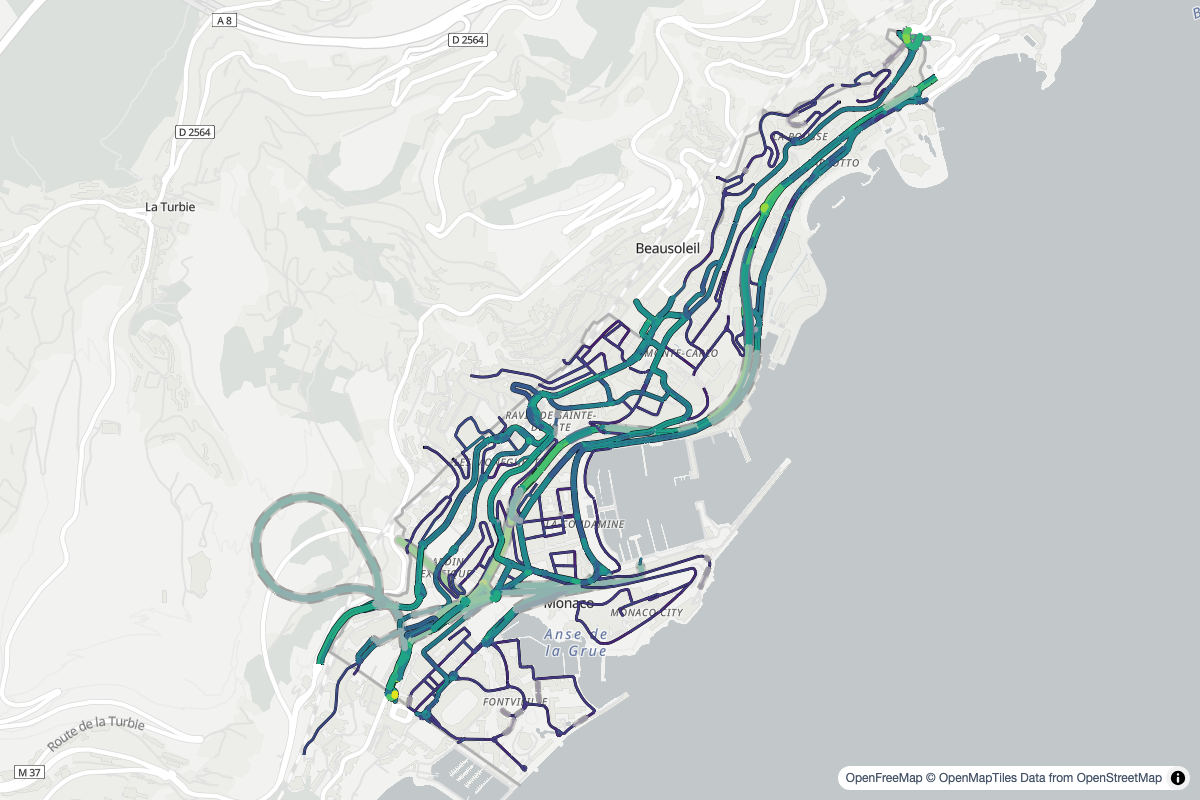

In [18]:
predicted_speed = result.set_index("edge_id").predicted_kmh.rename("predicted km/h")   # keyed by edge_id
net.driving.map(color_by=predicted_speed)                                                # the map

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-output.svg" width="18" height="18" alt=""> **What the output shows**
>
> The main streets along the coast and through the middle of the city have the highest predicted speeds (green and yellow). The small streets have the lowest (dark blue). The edges in tunnels are pale, for example the loop in the west. Each color comes from the `edge_id` of its edge.

## What to do next

- Use a measured target: traffic counts or sensor data joined by `edge_id` (chapters 4 and 11).
- Add your own columns to `x`, as in "Add your own column".
- Try other layers of PyG, for example `SAGEConv` or `GATConv`, in place of `GCNConv`.
- Train on one area and test on another. Put the feature columns of the two areas in the same order first.

> <img src="https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/notebooks/images/icon-tip.svg" width="18" height="18" alt=""> **Tip**
>
> For graph algorithms without a model (shortest paths, centrality, connected parts), use the networkx and rustworkx graphs of chapter 7, "As a graph": `net.driving.to_networkx()` and `net.driving.to_rustworkx()`. `duckosm.ml.to_networkx_nodes(net.driving)` gives the junction graph as a networkx `MultiDiGraph` in the layout of OSMnx.

This is the last chapter of the notebook manual. Each chapter is in the [notebook manual](index.md), and the
[Python SDK reference](../reference/python.md) has every call.

## Try it yourself

**1.** Make the junction graph with the features `length_m` and `highway`. How many columns has `edge_attr`?

<details><summary>Show the answer</summary>

```python
a = duckosm.ml.graph_arrays(net.driving, features=["length_m", "highway"])
a["edge_attr"].shape, a["edge_attr_names"]
```
</details>

**2.** Find the `edge_id` and the predicted speed of row number 100 of the turn graph, and the name of its edge.

<details><summary>Show the answer</summary>

```python
e = int(turns.edge_id[100])
e, float(predicted[100]), result.set_index("edge_id").loc[e, "name"]
```
</details>

**3.** Make the turn graph again with the two count columns of "Add your own column" as more features, and scale the features.

<details><summary>Show the answer</summary>

```python
own = duckosm.ml.to_pyg(net.driving, graph="turns", features=["length_m", "lanes", "highway"])
extra = torch.tensor(np.column_stack([vph.fillna(0), has_count]), dtype=torch.float32)
own.x = torch.cat([own.x, extra], dim=1)                        # 12 + 2 columns
own.x = (own.x - own.x.mean(0)) / (own.x.std(0) + 1e-6)
own.num_node_features                                           # then train SpeedModel(14) on own
```
</details>

## Words in this chapter

| Word | Meaning |
|---|---|
| graph machine learning | a model that learns a value for each vertex or arc of a graph from features and neighbors |
| node | a junction of the duckOSM network (`node_id`) |
| edge | one direction of a road in duckOSM (`edge_id`) |
| turn | a legal move from one edge to the next edge (a row of `edge_graph`) |
| vertex | a dot of the graph that a model reads. PyTorch Geometric and DGL call it a node |
| arc | a line from one vertex to another vertex |
| row number | the position of a vertex or an arc in the tables (0, 1, 2 ...) |
| junction graph | a graph where each node is a vertex and each edge is an arc (`graph="nodes"`) |
| turn graph | a graph where each edge becomes a vertex and each turn is an arc (`graph="turns"`) |
| feature | a number that describes a vertex or an arc, as input to a model |
| one-hot column | a 0/1 column for one value of a text column, for example `highway=primary` |
| tensor | an array of numbers in PyTorch |
| target | the value that the model learns and predicts, here the speed limit (`y` in PyG) |
| mask | a true/false array that selects the row numbers to train or to test |
| graph convolution (GCN) | a layer that mixes the features of a vertex with those of its neighbors |

## Summary

| Call | Does |
|---|---|
| `duckosm.ml.graph_arrays(net.driving, graph="nodes", features=...)` | the arc and feature arrays as NumPy, with `edge_id` and `node_id` |
| `duckosm.ml.DEFAULT_FEATURES` | the default features: `length_m`, `maxspeed_kmh`, `lanes` |
| `duckosm.ml.to_pyg(net.driving, graph="turns", features=...)` | a PyTorch Geometric `Data` object, with `edge_id` |
| `duckosm.ml.to_dgl(net.driving, graph="nodes", features=...)` | a `dgl.DGLGraph` (needs dgl) |
| `net.driving.map(color_by=series)` | a map colored by a Series keyed by `edge_id` |
| `to_networkx`, `to_networkx_nodes`, `to_rustworkx` | the graph for networkx and rustworkx (chapter 7) |

The reference: [duckosm.ml](../reference/sdk/ml.md).